# Notebook 02 — Dataset BTC15m para walk-forward

# 02 — Construcción del dataset y análisis exploratorio

A partir de los JSON del notebook 01 construyo una observación por contrato y minuto. El objetivo es reunir la información disponible al momento de la decisión y la resolución final del contrato, sin mezclar ambas cosas.

**Entradas:** archivos de Kalshi y BRTI en `data/raw/`. **Salidas:** dataset en `data/processed/`, gráficos exploratorios y auditoría de calidad. El período efectivo se define con `START` y `END` en la celda siguiente (UTC, extremo final excluido).

Los precios YES de Kalshi se expresan en dólares por contrato, entre 0 y 1. Las velas históricas usan tanto `close` como `close_dollars`: comprobé en los JSON de julio y agosto que ambos formatos ya están en dólares. No corresponde dividir el formato antiguo por 100.

Las velas de un minuto son información agregada, no cotizaciones ejecutables. Su marca temporal indica el cierre del intervalo, no necesariamente cuándo estuvo publicada la vela.


La columna `exploratory_split` se usa únicamente en los gráficos descriptivos. Los notebooks 03 y 04 recalculan cada fold temporal sin usarla.

Para que octubre sea completo, el notebook 01 descarga hasta el 1 de noviembre (fin exclusivo). Si se reutilizan archivos anteriores, hay que completar las horas y velas faltantes.

In [1]:
# Ejecutar una vez si faltan paquetes:
# %pip install pandas numpy matplotlib scikit-learn pyarrow

import json, gzip, ast, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

RAW = Path('data/raw')
OUT = Path('data/processed')
FIG = Path('figures')
OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)
START = pd.Timestamp('2025-12-01', tz='UTC')
END = pd.Timestamp('2026-11-01', tz='UTC')
LAMBDA = 0.96
LAG_SECONDS = 2
REQUIRE_FULL_BRTI = True  # Exigir archivos para todas las horas del período; no exige todos los ticks
assert START < END
print('Carpeta de datos:', RAW.resolve())

Carpeta de datos: /home/fernando/Downloads/data/raw


## 1. Lectura de Kalshi

El notebook de descarga guardó `kalshi/markets.json` y un JSON de candlesticks por ticker. Leo esos archivos sin modificar los originales. Las velas son OHLC por minuto, **no** snapshots de bid/ask; no voy a inventar un spread a partir de ellas. Si una vela contiene `yes_bid`/`yes_ask`, conservo sus cierres de vela como referencias históricas; no representan necesariamente cotizaciones ejecutables en el instante de decisión.

Para el instante de decisión uso el **fin de la vela** (su `end_period_ts`). Así no utilizo el cierre de una vela que todavía no había terminado. Esto es una convención conservadora para investigación; la latencia de publicación histórica no está certificada.

In [2]:
def read_json(path):
    with open(path, encoding='utf-8') as f:
        return json.load(f)

def unix_s(x):
    if x is None or x == '':
        return np.nan
    if isinstance(x, (int, float)):
        return float(x) / 1000 if float(x) > 1e11 else float(x)
    try:
        return pd.Timestamp(x).timestamp()
    except (TypeError, ValueError):
        return np.nan

def first_number(obj, paths):
    for path in paths:
        x = obj
        for key in path.split('.'):
            x = x.get(key) if isinstance(x, dict) else None
        if x is not None:
            try:
                return float(x)
            except (TypeError, ValueError):
                pass
    return np.nan

markets_file = RAW / 'kalshi/markets.json'
assert markets_file.exists(), f'Falta {markets_file}. Ejecutá primero el notebook de descarga.'
market_obj = read_json(markets_file)
markets = market_obj.get('markets', [])
print('Mercados listados:', len(markets))
print('Paginación:', {k:v for k,v in market_obj.items() if 'pagination' in k})
print('Ejemplo de campos:', sorted(markets[0]) if markets else [])

Mercados listados: 30381
Paginación: {'live_pagination_complete': True, 'archived_pagination_complete': True}
Ejemplo de campos: ['_catalog_source', 'can_close_early', 'close_time', 'created_time', 'event_ticker', 'exchange_index', 'expected_expiration_time', 'expiration_time', 'expiration_value', 'last_price_dollars', 'latest_expiration_time', 'market_type', 'no_ask_dollars', 'no_bid_dollars', 'no_sub_title', 'notional_value_dollars', 'open_interest_fp', 'open_time', 'previous_price_dollars', 'previous_yes_ask_dollars', 'previous_yes_bid_dollars', 'price_level_structure', 'price_ranges', 'result', 'rules_primary', 'rules_secondary', 'settlement_bounds_type', 'settlement_timer_seconds', 'settlement_ts', 'settlement_value_dollars', 'status', 'ticker', 'title', 'updated_time', 'volume_24h_fp', 'volume_fp', 'yes_ask_dollars', 'yes_ask_size_fp', 'yes_bid_dollars', 'yes_bid_size_fp', 'yes_sub_title']


**Corrección de escala (verificada con JSON históricos):** los campos legacy `price.close`, `yes_bid.close` y `yes_ask.close` ya están en USD, igual que `close_dollars`. No se dividen por 100. Se preservan controles de rango y auditoría de distribución.


In [3]:
def parse_outcome(m):
    x = str(m.get('result') or m.get('outcome') or '').strip().lower()
    return {'yes': 1, 'no': 0}.get(x, np.nan)

# Verificado con JSON históricos: los campos price.close / yes_bid.close / yes_ask.close
# antiguos ya están en USD, igual que los campos nuevos *_dollars.
# Ejemplos observados: julio price.close="0.6400"; agosto price.close_dollars="0.4300".
# No convertir por fecha ni dividir por 100.
def raw_field(c, path):
    x = c
    for key in path.split('.'):
        x = x.get(key) if isinstance(x, dict) else None
    if x is None:
        return None
    try:
        return float(x)
    except (TypeError, ValueError):
        return None

def parse_price_field(c, paths):
    for path in paths:
        value = raw_field(c, path)
        if value is None or not np.isfinite(value):
            continue
        if not 0 <= value <= 1:
            raise ValueError(f'Precio Kalshi fuera de [0,1]: {path}={value}')
        return value, path
    return np.nan, 'missing'

# Pruebas de regresión para ambos formatos, incluido bid/ask.
assert parse_price_field({'price': {'close': '0.6400'}}, ['price.close_dollars', 'price.close'])[0] == .64
assert parse_price_field({'price': {'close_dollars': '0.4300'}}, ['price.close_dollars', 'price.close'])[0] == .43
assert parse_price_field({'yes_bid': {'close': '0.6300'}}, ['yes_bid.close_dollars', 'yes_bid.close'])[0] == .63
assert parse_price_field({'yes_ask': {'close_dollars': '0.4400'}}, ['yes_ask.close_dollars', 'yes_ask.close'])[0] == .44

def trade_close(c):
    return parse_price_field(c, ['price.close_dollars','yes_price.close_dollars',
                                 'price.close','yes_price.close'])

def quote_close(c, side):
    return parse_price_field(c, [f'{side}.close_dollars',f'{side}.close'])

rows, contract_rows, missing_candles = [], [], []
for m in markets:
    ticker = m.get('ticker')
    if not ticker: continue
    close = unix_s(m.get('close_time') or m.get('expected_expiration_time'))
    if not np.isfinite(close) or not START.timestamp() <= close < END.timestamp():
        continue
    start = close - 900  # Ventana nominal de 15 minutos; auditar contra reglas oficiales.
    contract_rows.append({'ticker':ticker,'contract_start_ts':int(start),
                          'contract_close_ts':int(close),'target_yes':parse_outcome(m),
                          'result_raw':m.get('result'),'strike_api':first_number(m,['floor_strike','strike_price'])})
    path = RAW / 'kalshi/candles' / f'{ticker}.json'
    if not path.exists():
        missing_candles.append(ticker)
        continue
    candles = read_json(path).get('candlesticks', [])
    for c in candles:
        candle_end = unix_s(c.get('end_period_ts') or c.get('end_time'))
        if not np.isfinite(candle_end): continue
        # El período de una vela de un minuto termina en end_period_ts.
        decision = int(candle_end)
        if not start < decision < close: continue
        yes_close, close_source = trade_close(c)
        bid, bid_source = quote_close(c, 'yes_bid')
        ask, ask_source = quote_close(c, 'yes_ask')
        rows.append({'ticker':ticker,'decision_ts':decision,'kalshi_yes_close':yes_close,
                     'kalshi_yes_bid':bid,'kalshi_yes_ask':ask,
                     'kalshi_close_field':close_source,
                     'kalshi_bid_field':bid_source,'kalshi_ask_field':ask_source,
                     'candle_end_ts':int(candle_end)})

contracts = pd.DataFrame(contract_rows).drop_duplicates('ticker')
assert len(contracts), 'No se encontraron contratos en el período.'
assert len(rows), 'No se encontraron velas utilizables. Revisar formato de end_period_ts y carpetas.'
kalshi = pd.DataFrame(rows).sort_values(['ticker','decision_ts']).drop_duplicates(['ticker','decision_ts'])
kalshi = kalshi.merge(contracts, on='ticker', validate='many_to_one')
kalshi['minutes_remaining'] = (kalshi.contract_close_ts-kalshi.decision_ts)/60
# Midpoint solo cuando hay bid y ask; nunca completar artificialmente con cierre.
kalshi['kalshi_yes_mid'] = (kalshi.kalshi_yes_bid+kalshi.kalshi_yes_ask)/2
kalshi.loc[kalshi.kalshi_yes_bid > kalshi.kalshi_yes_ask, 'kalshi_yes_mid'] = np.nan
kalshi['kalshi_yes_price_proxy'] = kalshi.kalshi_yes_close.combine_first(kalshi.kalshi_yes_mid)
kalshi['kalshi_price_source'] = np.select(
    [kalshi.kalshi_yes_close.notna(),kalshi.kalshi_yes_mid.notna()],
    ['candle_close','bid_ask_mid'],default='missing')
kalshi['kalshi_spread'] = kalshi.kalshi_yes_ask-kalshi.kalshi_yes_bid
print('Contratos:',len(contracts),'| con velas:',kalshi.ticker.nunique(),
      '| faltantes:',len(missing_candles),'| observaciones:',len(kalshi))
print('Cierres de operación:', int(kalshi.kalshi_yes_close.notna().sum()),
      '| Midpoints bid/ask:', int(kalshi.kalshi_yes_mid.notna().sum()))
assert kalshi.kalshi_yes_price_proxy.notna().any(), 'No se pudieron leer precios Kalshi: revisar formato del JSON de candlesticks.'
display(kalshi.head())
# Comprobar que los precios se interpretaron correctamente antes de continuar.
print(kalshi[['kalshi_yes_close','kalshi_yes_bid','kalshi_yes_ask','kalshi_yes_mid','kalshi_yes_price_proxy']].notna().sum())

print('Campos de origen del cierre:',kalshi.kalshi_close_field.value_counts().to_dict())
print('Campos de origen bid:',kalshi.kalshi_bid_field.value_counts().to_dict())
print('Campos de origen ask:',kalshi.kalshi_ask_field.value_counts().to_dict())
assert kalshi[['kalshi_yes_close','kalshi_yes_bid','kalshi_yes_ask']].stack().between(0,1).all(), 'Precio Kalshi fuera de [0,1]'


Contratos: 30381 | con velas: 30272 | faltantes: 0 | observaciones: 423135
Cierres de operación: 416625 | Midpoints bid/ask: 423135


,ticker,decision_ts,kalshi_yes_close,kalshi_yes_bid,kalshi_yes_ask,kalshi_close_field,kalshi_bid_field,kalshi_ask_field,candle_end_ts,contract_start_ts,contract_close_ts,target_yes,result_raw,strike_api,minutes_remaining,kalshi_yes_mid,kalshi_yes_price_proxy,kalshi_price_source,kalshi_spread
0,KXBTC15M-25DEC101715-15,1765404540,NaN,0.4,1.00,missing,yes_bid.close,yes_ask.close,1765404540,1765404000,1765404900,0,no,NaN,6.0,0.700,0.700,bid_ask_mid,0.60
1,KXBTC15M-25DEC101845-45,1765409520,NaN,0.0,1.00,missing,yes_bid.close,yes_ask.close,1765409520,1765409400,1765410300,0,no,NaN,13.0,0.500,0.500,bid_ask_mid,1.00
2,KXBTC15M-25DEC101915-15,1765411680,NaN,0.0,0.95,missing,yes_bid.close,yes_ask.close,1765411680,1765411200,1765412100,1,yes,NaN,7.0,0.475,0.475,bid_ask_mid,0.95
3,KXBTC15M-25DEC101915-15,1765411740,NaN,0.0,1.00,missing,yes_bid.close,yes_ask.close,1765411740,1765411200,1765412100,1,yes,NaN,6.0,0.500,0.500,bid_ask_mid,1.00
4,KXBTC15M-25DEC101930-30,1765412940,NaN,0.0,0.20,missing,yes_bid.close,yes_ask.close,1765412940,1765412100,1765413000,0,no,NaN,1.0,0.100,0.100,bid_ask_mid,0.20


kalshi_yes_close          416625
kalshi_yes_bid            423135
kalshi_yes_ask            423135
kalshi_yes_mid            423135
kalshi_yes_price_proxy    423135
dtype: int64
Campos de origen del cierre: {'price.close': 332989, 'price.close_dollars': 83636, 'missing': 6510}
Campos de origen bid: {'yes_bid.close': 339499, 'yes_bid.close_dollars': 83636}
Campos de origen ask: {'yes_ask.close': 339499, 'yes_ask.close_dollars': 83636}


### Campos que deliberadamente no se exportan

- **Volumen:** la descarga actual utiliza velas de un minuto. No se extrae un volumen por contrato/minuto sin comprobar primero su presencia, definición y unidad en los JSON crudos.
- **Open interest:** no es una variable de las velas descargadas en este flujo; no se genera una columna de `NaN`. Si en el futuro se incorpora, debe descargarse de una fuente con timestamps y significado documentados.
- **Bid/ask:** `yes_bid.close` y `yes_ask.close` son cierres de series de velas; el midpoint es una referencia descriptiva, no prueba de liquidez ni de ejecución.
- **Resultado final:** `target_yes` se conserva únicamente como etiqueta; no debe introducirse en las features del modelo.


## 2. BRTI original de Kalshi

Cada archivo `data/raw/brti/YYYYMMDDTHHZ.json.gz` puede contener hasta 18.000 observaciones por hora a 5 Hz. Para trabajar a escala de minuto no necesito cargar todos los ticks en memoria: selecciono los timestamps exactos de segundo y después el minuto exacto. No interpolo faltantes.

El strike se reconstruye como el promedio de los 60 segundos anteriores al inicio de la ventana, **solo si están todos los segundos**. El predictor BRTI usa la media de los 60 segundos que terminan dos segundos antes de la decisión: `mean([t-62,t-2))`. Esa reconstrucción no demuestra que el strike se hubiera publicado a tiempo.

**Importante:** una hora con menos de 18.000 ticks no se descarta automáticamente. Se documentan los huecos y se validan las ventanas utilizadas por cada observación.


In [4]:
brti_files = sorted((RAW/'brti').glob('*.json.gz'))
assert brti_files, f'No hay archivos BRTI en {RAW/"brti"}.'
second_values = []
hour_audit = []
for file in brti_files:
    try:
        with gzip.open(file,'rt',encoding='utf-8') as f: obj=json.load(f)
        vals=obj.get('values',[])
        hour_audit.append({'file':file.name,'ticks':len(vals),
                           'unique_timestamps':len({int(t) for t,_ in vals})})
        # Usar ticks exactamente en el segundo entero.
        second_values.extend((int(t)//1000,float(v)) for t,v in vals if int(t)%1000==0)
    except (OSError,ValueError,KeyError,TypeError) as exc:
        hour_audit.append({'file':file.name,'error':str(exc)})

hour_audit = pd.DataFrame(hour_audit)
sec = (pd.DataFrame(second_values,columns=['second','brti_price'])
       .drop_duplicates('second').sort_values('second').set_index('second')['brti_price'])
sec = sec[(sec.index>=int(START.timestamp())-60)&(sec.index<int(END.timestamp()))]
assert not sec.empty, 'Los archivos BRTI no contienen ticks a segundo exacto.'
print('Archivos BRTI:',len(brti_files),'| horas esperadas:',len(pd.date_range(START, END, freq='h', inclusive='left')))
print('Segundos disponibles:',len(sec),'| segundos del período:',int((END-START).total_seconds()))
display(hour_audit.head())
# Las horas pueden estar presentes aunque haya pequeños huecos de origen.
# Validamos cobertura por hora y registramos gaps, sin rellenarlos.
expected_hours = pd.date_range(START, END, freq='h', inclusive='left')
expected_names = {t.strftime('%Y%m%dT%HZ.json.gz') for t in expected_hours}
actual_names = {f.name for f in brti_files}
missing_hours = sorted(expected_names - actual_names)
failed_hours = hour_audit.loc[hour_audit.get('error', pd.Series(index=hour_audit.index, dtype='object')).notna(), 'file'].tolist()
if REQUIRE_FULL_BRTI and (missing_hours or failed_hours):
    raise RuntimeError(f'Faltan horas BRTI o no se pudieron leer: {missing_hours[:8]} / {failed_hours[:8]}')

# No confundir 720/720 archivos con 100% de segundos completos.
expected_sec = np.arange(int(START.timestamp()), int(END.timestamp()), dtype=np.int64)
missing_sec = np.setdiff1d(expected_sec, sec.index.to_numpy(), assume_unique=True)
print(f'Horas presentes: {len(expected_names & actual_names)}/{len(expected_names)}; '
      f'segundos ausentes: {len(missing_sec):,}/{len(expected_sec):,}')
if len(missing_sec):
    print('Primeros segundos ausentes (UTC):',
          pd.to_datetime(missing_sec[:8], unit='s', utc=True).tolist())

# Detectar discontinuidades entre segundos consecutivos y guardarlas para auditoría.
idx = sec.index.to_numpy()
delta = np.diff(idx)
gap_positions = np.flatnonzero(delta > 1)
brti_gaps = pd.DataFrame([
    {'last_available_utc': pd.to_datetime(int(idx[i]), unit='s', utc=True),
     'next_available_utc': pd.to_datetime(int(idx[i+1]), unit='s', utc=True),
     'missing_seconds': int(delta[i] - 1)}
    for i in gap_positions
])
print('Discontinuidades entre segundos BRTI:', len(brti_gaps))
if not brti_gaps.empty:
    display(brti_gaps.head(12))


Archivos BRTI: 8040 | horas esperadas: 8040
Segundos disponibles: 28933441 | segundos del período: 28944000


,file,ticks,unique_timestamps
0,20251201T00Z.json.gz,3600,3600
1,20251201T01Z.json.gz,3600,3600
2,20251201T02Z.json.gz,3600,3600
3,20251201T03Z.json.gz,3600,3600
4,20251201T04Z.json.gz,3600,3600


Horas presentes: 8040/8040; segundos ausentes: 10,559/28,944,000
Primeros segundos ausentes (UTC): [Timestamp('2025-12-02 12:21:36+0000', tz='UTC'), Timestamp('2025-12-02 12:21:37+0000', tz='UTC'), Timestamp('2025-12-02 12:21:38+0000', tz='UTC'), Timestamp('2025-12-02 12:21:39+0000', tz='UTC'), Timestamp('2025-12-02 12:21:40+0000', tz='UTC'), Timestamp('2025-12-02 12:21:41+0000', tz='UTC'), Timestamp('2025-12-02 12:21:42+0000', tz='UTC'), Timestamp('2025-12-02 12:21:43+0000', tz='UTC')]
Discontinuidades entre segundos BRTI: 620


,last_available_utc,next_available_utc,missing_seconds
0,2025-12-02 12:21:35+00:00,2025-12-02 12:21:48+00:00,12
1,2025-12-02 22:39:02+00:00,2025-12-02 22:39:21+00:00,18
2,2025-12-02 22:40:00+00:00,2025-12-02 22:40:14+00:00,13
3,2025-12-03 22:39:01+00:00,2025-12-03 22:39:21+00:00,19
4,2025-12-03 22:40:00+00:00,2025-12-03 22:40:13+00:00,12
5,2025-12-04 22:39:00+00:00,2025-12-04 22:39:21+00:00,20
6,2025-12-04 22:40:00+00:00,2025-12-04 22:40:15+00:00,14
7,2025-12-08 16:59:40+00:00,2025-12-08 17:00:00+00:00,19
8,2025-12-16 22:39:00+00:00,2025-12-16 22:39:20+00:00,19
9,2025-12-17 22:39:01+00:00,2025-12-17 22:39:20+00:00,18


In [5]:
# Una ventana de 60 segundos solo vale si contiene 60 segundos consecutivos.
mean60 = sec.rolling(60,min_periods=60).mean()
continuous = pd.Series(sec.index.to_numpy(),index=sec.index).diff().eq(1)
mean60 = mean60.where(continuous.rolling(59,min_periods=59).sum().eq(59))

def means_before(ts):
    # La media de [t-60,t) termina en t-1.
    return mean60.reindex(np.asarray(ts,dtype=np.int64)-1).to_numpy()

kalshi['strike_reconstructed'] = means_before(kalshi.contract_start_ts)
kalshi['brti_mean_60s'] = means_before(kalshi.decision_ts-LAG_SECONDS)
# Si el strike oficial viene de la API, no reemplazarlo por una estimación.
kalshi['strike'] = kalshi.strike_api.combine_first(kalshi.strike_reconstructed)
kalshi['strike_source'] = np.where(kalshi.strike_api.notna(),'api',
                                  np.where(kalshi.strike_reconstructed.notna(),'reconstructed','missing'))
kalshi['brti_distance_to_strike_pct'] = 100*(kalshi.brti_mean_60s/kalshi.strike-1)
print(kalshi.strike_source.value_counts(dropna=False).to_string())
print('Medias BRTI completas:',kalshi.brti_mean_60s.notna().sum())

strike_source
api              418733
reconstructed      4374
missing              28
Medias BRTI completas: 422543


## 3. Retornos y EWMA

Reproduzco la metodología auditada: tomo el BRTI en cada minuto exacto, calculo retornos logarítmicos y aplico EWMA a los retornos al cuadrado.

\[r_t=\log(S_t/S_{t-1}),\qquad \widehat\sigma_t^2=\lambda\widehat\sigma_{t-1}^2+(1-\lambda)r_t^2\]

La volatilidad que grafico es `sqrt(EWMA)*10000`, en puntos básicos por raíz de minuto. Uso λ = 0,96 para dar más peso a los retornos recientes. No ajusto este parámetro con los resultados del test.

El predictor en una decisión usa el último minuto disponible hasta `decision_ts - 2 s`, sin mirar hacia adelante.

In [6]:
minute = sec[sec.index % 60 == 0].rename('brti_price').to_frame()
# Retorno de un minuto: exigir los 61 segundos de la trayectoria [t-60, t],
# no solo los dos extremos; de otro modo se ignorarían huecos intermedios.
minute_seconds_complete = (sec.rolling(61, min_periods=61).count().eq(61) &
    pd.Series(sec.index.to_numpy(), index=sec.index).diff().eq(1).rolling(60, min_periods=60).sum().eq(60))
minute['quality_return_1m_continuous'] = (minute_seconds_complete.reindex(minute.index).fillna(False).astype(bool) &
    pd.Series(minute.index.to_numpy(), index=minute.index).diff().eq(60))
minute['return_1m'] = np.log(minute.brti_price).diff().where(minute['quality_return_1m_continuous'])
minute['ewma_var'] = minute.return_1m.pow(2).ewm(
    alpha=1-LAMBDA,adjust=False,ignore_na=True,min_periods=60).mean()
minute['ewma_volatility_bps_min'] = np.sqrt(minute.ewma_var)*10000
# El EWM con ignore_na conserva su estado cuando faltan retornos. Por prudencia,
# marcamos no aptos los primeros 60 retornos tras una discontinuidad.
minute['quality_ewma_continuous'] = (minute['quality_return_1m_continuous']
    .rolling(60, min_periods=60).sum().eq(60))
minute.loc[~minute['quality_ewma_continuous'], 'ewma_volatility_bps_min'] = np.nan
minute = minute.reset_index().rename(columns={'second':'brti_timestamp'})
kalshi['_order'] = np.arange(len(kalshi))
kalshi['brti_cutoff_ts'] = kalshi.decision_ts-LAG_SECONDS
kalshi = pd.merge_asof(kalshi.sort_values('brti_cutoff_ts'),
                       minute.sort_values('brti_timestamp'),
                       left_on='brti_cutoff_ts',right_on='brti_timestamp',
                       direction='backward',tolerance=120).sort_values('_order').drop(columns='_order')
assert (kalshi.loc[kalshi.brti_timestamp.notna(),'brti_timestamp'] <=
        kalshi.loc[kalshi.brti_timestamp.notna(),'brti_cutoff_ts']).all()
kalshi['brti_return_1m'] = kalshi['return_1m']
print('EWMA disponible:',kalshi.ewma_volatility_bps_min.notna().sum())

EWMA disponible: 399800


## 5. Validación y partición temporal

El dataset final contiene **solo tres indicadores interpretables**: `brti_complete`, `ewma_valid` y `valid_for_training`. Las comprobaciones de precios, strikes, bid/ask y timestamps siguen ejecutándose en el código, pero se resumen en `auditoria_dataset.json` en vez de generar columnas booleanas adicionales.


**Importante:** el split exploratorio exportado es orientativo. El walk-forward se define por fechas de contratos en los notebooks 03/04.

In [7]:
df = kalshi.copy().sort_values(['contract_start_ts', 'ticker', 'decision_ts']).reset_index(drop=True)

# Comprobaciones internas (no se exportan como columnas independientes).
checks = {
    'kalshi_candle': df.kalshi_yes_close.between(0, 1),
    'kalshi_bid_ask': (df.kalshi_yes_bid.between(0, 1) &
                      df.kalshi_yes_ask.between(0, 1) &
                      df.kalshi_yes_bid.le(df.kalshi_yes_ask)),
    'strike_api': df.strike_source.eq('api'),
    'strike_reconstructed': df.strike_reconstructed.notna(),
}

# Predicción inmediatamente DESPUÉS del cierre de la vela contemporánea.
# end_period_ts es fin del intervalo, NO prueba del instante de publicación.
# Se conserva candle_end_ts para comprobar causalidad; el retraso real de API no es observable.
df['kalshi_feature_candle_end_ts'] = df.candle_end_ts
df['kalshi_feature_age_seconds'] = df.decision_ts - df.kalshi_feature_candle_end_ts
checks['kalshi_current_candle'] = (
    df.kalshi_yes_price_proxy.between(0, 1) &
    df.kalshi_feature_candle_end_ts.le(df.decision_ts) &
    df.kalshi_feature_age_seconds.ge(0)
)
checks['exploratory'] = (df.kalshi_yes_price_proxy.between(0, 1) &
                         df.brti_distance_to_strike_pct.notna() &
                         df.target_yes.isin([0, 1]))

# Tres banderas interpretables; sin dependencia de lag 1.
df['brti_complete'] = df.brti_mean_60s.notna()
df['ewma_valid'] = df.ewma_volatility_bps_min.notna()
df['valid_for_training'] = (checks['strike_api'] & df.brti_complete &
                            df.ewma_valid & checks['kalshi_current_candle'] &
                            df.brti_return_1m.notna() &
                            df.target_yes.isin([0, 1]))

ct = df[['ticker', 'contract_start_ts']].drop_duplicates().sort_values(
    ['contract_start_ts', 'ticker']).reset_index(drop=True)
n = len(ct)
# Split de referencia SOLO para diagnósticos del Notebook 02.
# Los notebooks 03/04 crean los folds walk-forward desde timestamps,
# y NO usan esta columna para entrenar ni evaluar.
ct['exploratory_split'] = np.select([ct.index < int(.40*n), ct.index < int(.50*n)],
                        ['train', 'validation'], default='test')
df = df.merge(ct[['ticker', 'exploratory_split']], on='ticker', validate='many_to_one')
assert df.groupby('ticker').exploratory_split.nunique().max() == 1
assert not df.duplicated(['ticker', 'decision_ts']).any()
assert (df.decision_ts < df.contract_close_ts).all()
assert df.target_yes.dropna().isin([0, 1]).all()
assert (df.loc[checks['kalshi_current_candle'], 'kalshi_feature_candle_end_ts'] <=
        df.loc[checks['kalshi_current_candle'], 'decision_ts']).all()

# Resumen de las comprobaciones sin ensuciar el dataset.
check_counts = {name: int(mask.sum()) for name, mask in checks.items()}
check_counts.update({name: int(df[name].sum()) for name in
                     ['brti_complete', 'ewma_valid', 'valid_for_training']})
print('Controles conservados:')
for name in ['brti_complete', 'ewma_valid', 'valid_for_training']:
    print(f'  {name}: {check_counts[name]:,} / {len(df):,}')
print('Comprobaciones adicionales: disponibles en auditoria_dataset.json')
display(df.groupby('exploratory_split').agg(contratos=('ticker', 'nunique'),
                                filas=('ticker', 'size'),
                                validas=('valid_for_training', 'sum')))

Controles conservados:
  brti_complete: 422,543 / 423,135
  ewma_valid: 399,800 / 423,135
  valid_for_training: 395,105 / 423,135
Comprobaciones adicionales: disponibles en auditoria_dataset.json


,contratos,filas,validas
exploratory_split,,,
test,15136,211863,202119
train,12108,168903,154581
validation,3028,42369,38405


## 6. Gráficos para el análisis exploratorio

El scatter utiliza `kalshi_yes_close` si hay operaciones; si no, usa `kalshi_yes_mid` como **proxy** y lo informa. No se interpreta como precio ejecutable. Solo se exige que las tres variables representadas sean válidas. `valid_for_training` se reserva para el dataset de entrenamiento y **no debe vaciar los gráficos**. Los gráficos descriptivos no equivalen a un backtest causal.

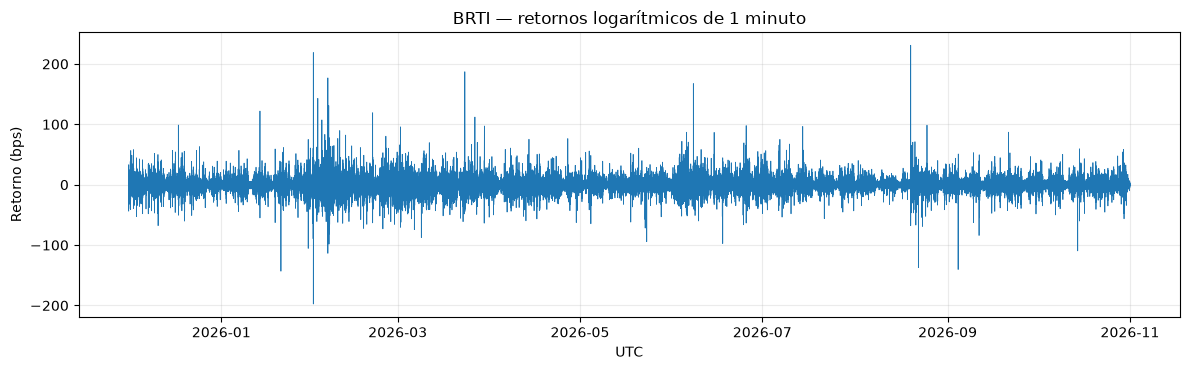

In [8]:
# Retornos BRTI (en puntos básicos)
ret=minute.dropna(subset=['return_1m']).copy()
ret['time']=pd.to_datetime(ret.brti_timestamp,unit='s',utc=True)
fig,ax=plt.subplots(figsize=(12,3.8))
ax.plot(ret.time,ret.return_1m*10000,lw=.55)
ax.set(title='BRTI — retornos logarítmicos de 1 minuto',ylabel='Retorno (bps)',xlabel='UTC')
ax.grid(alpha=.25);fig.tight_layout()
fig.savefig(FIG/'01_retornos_brti.png',dpi=170)
plt.show()

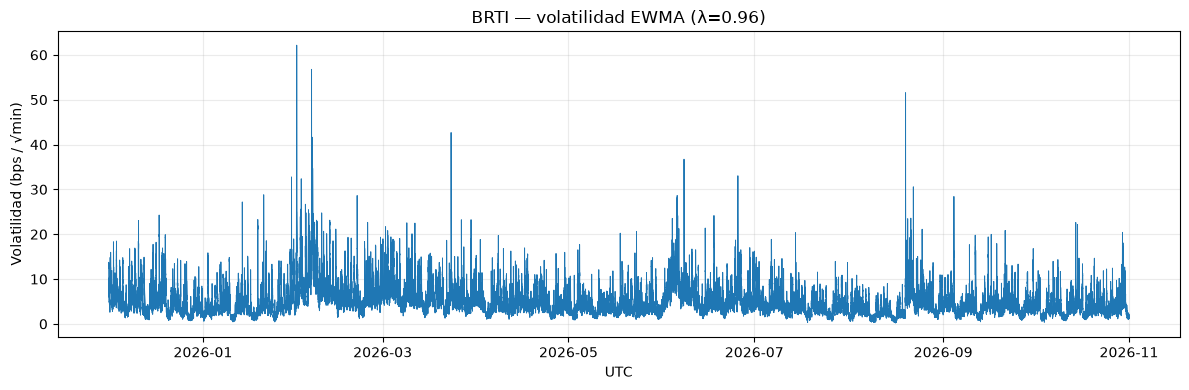

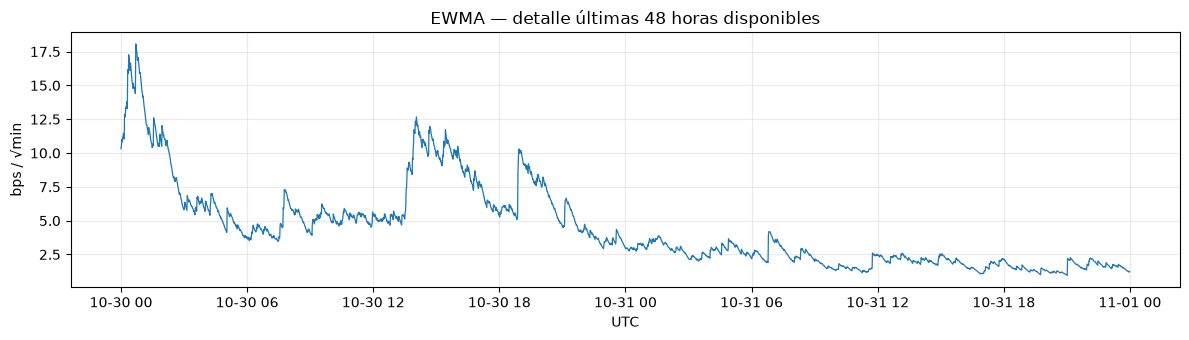

In [9]:
# EWMA de todo el período y detalle de las últimas 48 horas
vol=minute.dropna(subset=['ewma_volatility_bps_min']).copy()
vol['time']=pd.to_datetime(vol.brti_timestamp,unit='s',utc=True)
fig,ax=plt.subplots(figsize=(12,4))
ax.plot(vol.time,vol.ewma_volatility_bps_min,lw=.7)
ax.set(title=f'BRTI — volatilidad EWMA (λ={LAMBDA:.2f})',
       ylabel='Volatilidad (bps / √min)',xlabel='UTC')
ax.grid(alpha=.25);fig.tight_layout();fig.savefig(FIG/'02_ewma_brti_30d.png',dpi=170)
plt.show()
fig,ax=plt.subplots(figsize=(12,3.5))
recent=vol.tail(48*60)
ax.plot(recent.time,recent.ewma_volatility_bps_min,lw=.9)
ax.set(title='EWMA — detalle últimas 48 horas disponibles',ylabel='bps / √min',xlabel='UTC')
ax.grid(alpha=.25);fig.tight_layout();fig.savefig(FIG/'03_ewma_brti_48h.png',dpi=170)
plt.show()

In [10]:
# Auditoría de escala y plausibilidad ANTES de usar precios en gráficos/modelos.
# Los formatos históricos ya se leen en USD, sin dividir por 100.
# Una discontinuidad residual sigue siendo motivo para detenerse.
scale_audit = df.loc[df.minutes_remaining.eq(7)].copy()
scale_audit['date'] = pd.to_datetime(scale_audit.decision_ts, unit='s', utc=True).dt.date
scale_audit['low_price'] = scale_audit.kalshi_yes_close.lt(.01)
by_date = scale_audit.groupby('date').agg(n=('ticker','size'), low_pct=('low_price','mean'))
print('Fracción diaria con YES < USD 0.01 (7 min):')
print(by_date.to_string())
# La discontinuidad no se acepta silenciosamente.
if (by_date.n.ge(20).sum() >= 5 and
    by_date.loc[by_date.n.ge(20),'low_pct'].max() > .95 and
    by_date.loc[by_date.n.ge(20),'low_pct'].min() < .05):
    raise ValueError('Cambio extremo de escala/distribución detectado. '
                     'Revisar origen y distribución de precios Kalshi; '
                     'no entrenar hasta resolverlo.')

Fracción diaria con YES < USD 0.01 (7 min):
             n   low_pct
date                    
2025-12-11  43  0.000000
2025-12-12  58  0.000000
2025-12-13  25  0.000000
2025-12-14  59  0.000000
2025-12-15  60  0.000000
2025-12-16  57  0.000000
2025-12-17  60  0.000000
2025-12-18  79  0.000000
2025-12-19  96  0.000000
2025-12-20  92  0.000000
2025-12-21  96  0.000000
2025-12-22  96  0.000000
2025-12-23  96  0.000000
2025-12-24  96  0.000000
2025-12-25  88  0.000000
2025-12-26  94  0.000000
2025-12-27  96  0.000000
2025-12-28  64  0.000000
2025-12-29  28  0.000000
2025-12-30  34  0.000000
2025-12-31  87  0.000000
2026-01-01  88  0.000000
2026-01-02  96  0.000000
2026-01-03  96  0.000000
2026-01-04  96  0.000000
2026-01-05  96  0.000000
2026-01-06  96  0.000000
2026-01-07  96  0.000000
2026-01-08  88  0.000000
2026-01-09  96  0.000000
2026-01-10  96  0.000000
2026-01-11  92  0.000000
2026-01-12  96  0.000000
2026-01-13  96  0.000000
2026-01-14  96  0.000000
2026-01-15  88  0.000000
2026-0

## 7. Regímenes de volatilidad (análisis adicional)

La auditoría del trabajo anterior identificó tres centroides de EWMA: aproximadamente **2,81, 5,39 y 10,32 bps/√min**. Esos valores se obtuvieron ajustando k-means lineal sobre el período de entrenamiento original. El silhouette era mejor con dos clusters; tres se eligieron por interpretabilidad. Para no introducir información del test, en esta reconstrucción ajusto k-means **solo en train** y aplico esos centroides a validación y test. Por eso los valores pueden diferir ligeramente de los originales.

Centroides nuevos (train): [ 3.4945994   7.82443001 15.93659559]


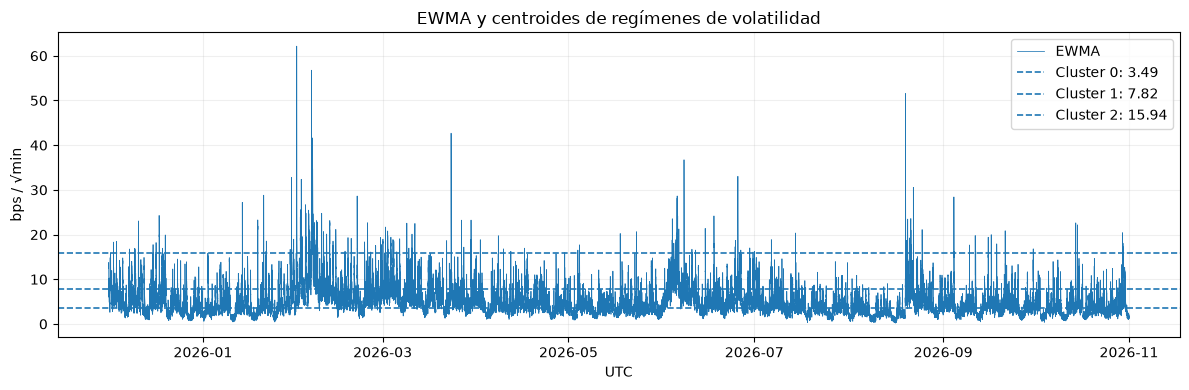

In [12]:
from sklearn.cluster import KMeans
train_vol=df.loc[df.exploratory_split.eq('train'),'ewma_volatility_bps_min'].dropna()
if len(train_vol)>=100:
    model=KMeans(n_clusters=3,random_state=42,n_init=20)
    model.fit(train_vol.to_numpy().reshape(-1,1))
    centers=model.cluster_centers_.ravel()
    ordering=np.argsort(centers)
    mapping={int(original):int(rank) for rank,original in enumerate(ordering)}
    df['vol_cluster']=pd.Series(pd.NA,index=df.index,dtype='Int64')
    mask=df.ewma_volatility_bps_min.notna()
    predictions=model.predict(df.loc[mask,'ewma_volatility_bps_min'].to_numpy().reshape(-1,1))
    df.loc[mask,'vol_cluster']=pd.array([mapping[int(i)] for i in predictions],dtype='Int64')
    print('Centroides nuevos (train):',np.sort(centers))
    fig,ax=plt.subplots(figsize=(12,4))
    ax.plot(vol.time,vol.ewma_volatility_bps_min,lw=.55,label='EWMA')
    for i,center in enumerate(np.sort(centers)):
        ax.axhline(center,ls='--',lw=1.2,label=f'Cluster {i}: {center:.2f}')
    ax.set(title='EWMA y centroides de regímenes de volatilidad',ylabel='bps / √min',xlabel='UTC')
    ax.grid(alpha=.2);ax.legend();fig.tight_layout()
    fig.savefig(FIG/'05_ewma_centroides.png',dpi=170);plt.show()
else:
    print('No hay observaciones suficientes para ajustar los clusters.')
    df['vol_cluster']=pd.Series(pd.NA,index=df.index,dtype='Int64')

## 8. Calibración de Kalshi YES (dataset completo, todos los minutos)

Se utilizan **todas las observaciones temporales del dataset completo** (no solo t=7). Los precios se agrupan al **centavo más cercano**: USD 0.00, 0.01, ..., 1.00. Cada punto representa la proporción observada de resultados YES entre las observaciones del bucket. El precio medio real dentro de cada bucket es la referencia para calcular el error con signo.

Un contrato puede aportar varias observaciones con el mismo resultado; por tanto, las filas **no son independientes** y el ECE calculado es ponderado por observaciones, no por contratos. Estos gráficos son descriptivos y usan train, validación y test conjuntamente; no deben utilizarse para seleccionar ni ajustar el modelo.

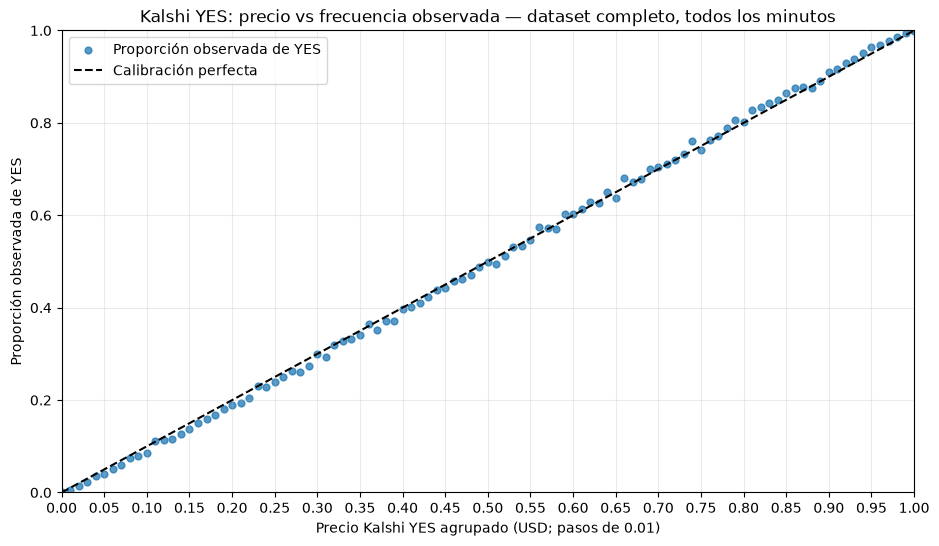

Observaciones: 416,625 | Contratos únicos: 30,239 | Buckets: 101


,precio,proporcion_yes,precio_medio,n
0,0.00,0.001013,0.001765,9868
1,0.01,0.005666,0.009409,13766
2,0.02,0.013693,0.019481,7011
3,0.03,0.022905,0.029549,5370
4,0.04,0.034977,0.039508,4603
...,...,...,...,...
96,0.96,0.967547,0.959809,4622
97,0.97,0.977221,0.969812,5224
98,0.98,0.984903,0.979875,6955
99,0.99,0.994644,0.989926,13629


In [14]:
# Precio Kalshi YES vs proporción observada de YES (resolución USD 0.01)
precio_col = 'kalshi_yes_close'
datos_cal = df[['ticker', 'minutes_remaining', precio_col, 'target_yes']].copy()
datos_cal[precio_col] = pd.to_numeric(datos_cal[precio_col], errors='coerce')
datos_cal = datos_cal.dropna(subset=[precio_col, 'target_yes'])
datos_cal = datos_cal.loc[datos_cal[precio_col].between(0, 1) & datos_cal.target_yes.isin([0, 1])].copy()
if datos_cal.empty:
    raise ValueError('No hay observaciones válidas de Kalshi YES en el dataset.')

# Redondeo al centavo más cercano, evitando artefactos de precisión binaria.
datos_cal['precio'] = (np.floor(datos_cal[precio_col].to_numpy() * 100 + 0.5).astype(int) / 100)
calibracion = (datos_cal.groupby('precio', as_index=False)
               .agg(proporcion_yes=('target_yes', 'mean'),
                    precio_medio=(precio_col, 'mean'),
                    n=('target_yes', 'size'))
               .sort_values('precio'))

fig, ax = plt.subplots(figsize=(11, 6))
ax.scatter(calibracion.precio, calibracion.proporcion_yes, s=24, alpha=0.75,
           label='Proporción observada de YES')
ax.plot([0, 1], [0, 1], 'k--', label='Calibración perfecta')
ax.set(xlabel='Precio Kalshi YES agrupado (USD; pasos de 0.01)',
       ylabel='Proporción observada de YES',
       title='Kalshi YES: precio vs frecuencia observada — dataset completo, todos los minutos',
       xlim=(0, 1), ylim=(0, 1))
ax.set_xticks(np.arange(0, 1.01, 0.05))
ax.grid(alpha=0.25)
ax.legend()
plt.show()
print(f'Observaciones: {len(datos_cal):,} | Contratos únicos: {datos_cal.ticker.nunique():,} | Buckets: {len(calibracion)}')
display(calibracion)

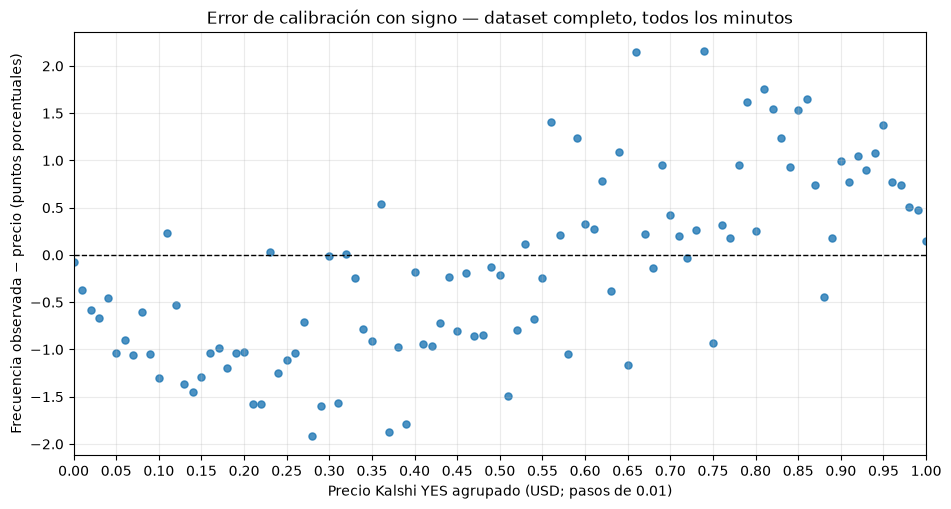

ECE (error absoluto ponderado): 0.774 puntos porcentuales
Sesgo medio con signo: -0.152 puntos porcentuales
Positivo = Kalshi subestima YES; negativo = Kalshi sobreestima YES.


,precio,precio_medio,proporcion_yes,n,error_firmado_pp,error_absoluto_pp
0,0.00,0.001765,0.001013,9868,-0.075122,0.075122
1,0.01,0.009409,0.005666,13766,-0.374255,0.374255
2,0.02,0.019481,0.013693,7011,-0.578862,0.578862
3,0.03,0.029549,0.022905,5370,-0.664376,0.664376
4,0.04,0.039508,0.034977,4603,-0.453118,0.453118
...,...,...,...,...,...,...
96,0.96,0.959809,0.967547,4622,0.773734,0.773734
97,0.97,0.969812,0.977221,5224,0.740888,0.740888
98,0.98,0.979875,0.984903,6955,0.502775,0.502775
99,0.99,0.989926,0.994644,13629,0.471803,0.471803


In [15]:
# Error de calibración CON SIGNO: observado - precio medio (puntos porcentuales)
error_cal = calibracion.copy()
error_cal['error_firmado_pp'] = 100 * (error_cal.proporcion_yes - error_cal.precio_medio)
error_cal['error_absoluto_pp'] = error_cal.error_firmado_pp.abs()

fig, ax = plt.subplots(figsize=(11, 5.5))
ax.scatter(error_cal.precio, error_cal.error_firmado_pp, s=26, alpha=0.8)
ax.axhline(0, color='black', linestyle='--', linewidth=1)
ax.set(xlabel='Precio Kalshi YES agrupado (USD; pasos de 0.01)',
       ylabel='Frecuencia observada − precio (puntos porcentuales)',
       title='Error de calibración con signo — dataset completo, todos los minutos',
       xlim=(0, 1))
ax.set_xticks(np.arange(0, 1.01, 0.05))
ax.grid(alpha=0.25)
plt.show()

ece_pp = np.average(error_cal.error_absoluto_pp, weights=error_cal.n)
sesgo_pp = np.average(error_cal.error_firmado_pp, weights=error_cal.n)
print(f'ECE (error absoluto ponderado): {ece_pp:.3f} puntos porcentuales')
print(f'Sesgo medio con signo: {sesgo_pp:+.3f} puntos porcentuales')
print('Positivo = Kalshi subestima YES; negativo = Kalshi sobreestima YES.')
display(error_cal[['precio', 'precio_medio', 'proporcion_yes', 'n', 'error_firmado_pp', 'error_absoluto_pp']])

## 8. Exportación y auditoría



In [16]:
# Columnas de análisis y modelado. No se exportan indicadores internos redundantes.
model_cols = [
    'ticker', 'contract_start_ts', 'contract_close_ts', 'decision_ts',
    'minutes_remaining', 'exploratory_split', 'target_yes',
    'kalshi_yes_close', 'kalshi_yes_bid', 'kalshi_yes_ask',
    'kalshi_yes_mid', 'kalshi_spread', 'kalshi_yes_price_proxy',
    'kalshi_price_source', 'kalshi_feature_candle_end_ts',
    'kalshi_feature_age_seconds', 'strike', 'strike_source', 'strike_api', 'strike_reconstructed',
    'brti_price', 'brti_mean_60s', 'brti_distance_to_strike_pct',
    'brti_return_1m', 'ewma_volatility_bps_min',
      
    'vol_cluster', 'brti_complete', 'ewma_valid', 'valid_for_training'
]
model_cols = [c for c in model_cols if c in df.columns]
full = df[model_cols].copy()
empty_cols = [c for c in full if full[c].isna().all()]
if empty_cols:
    print('Columnas totalmente vacías excluidas:', empty_cols)
    full = full.drop(columns=empty_cols)
core = full.loc[full.valid_for_training].copy()

for name, frame in [('dataset_completo', full), ('dataset_core', core)]:
    frame.to_csv(OUT / f'{name}.csv', index=False)
    try:
        frame.to_parquet(OUT / f'{name}.parquet', index=False)
    except (ImportError, ValueError) as exc:
        print('Parquet omitido:', name, exc)

report = {
    'period_start_utc': str(START),
    'period_end_exclusive_utc': str(END),
    'contracts_listed': len(contracts),
    'contracts_with_candles': int(df.ticker.nunique()),
    'missing_candle_contracts': missing_candles,
    'brti_hours_found': len(brti_files),
    'brti_hours_expected': len(expected_hours),
    'brti_missing_seconds': int(len(missing_sec)),
    'brti_discontinuities': int(len(brti_gaps)),
    'rows_all': len(full),
    'rows_core': len(core),
    'rows_exploratory': check_counts['exploratory'],
    'validation_counts': check_counts,
    'lambda': LAMBDA,
    'brti_predictor_lag_seconds': LAG_SECONDS,
    'missing_by_column': {k: int(v) for k, v in full.isna().sum().items()},
    'notes': [
        'Los tres indicadores exportados son brti_complete, ewma_valid y valid_for_training.',
        'El midpoint de una vela histórica no garantiza una cotización ejecutable.',
        'strike_source=api no certifica que el strike fuera conocido al decidir.',
        'No se verificó la latencia histórica de publicación de precios.',
        'El core usa la vela que acaba de cerrar; disponibilidad real de publicación no verificada.',
        'Los huecos BRTI se documentan sin interpolarlos.'
    ]
}
(OUT / 'auditoria_dataset.json').write_text(
    json.dumps(report, ensure_ascii=False, indent=2), encoding='utf-8')
hour_audit.to_csv(OUT / 'auditoria_horas_brti.csv', index=False)
brti_gaps.to_csv(OUT / 'auditoria_gaps_brti.csv', index=False)
print('Guardado en:', OUT.resolve())
print('Completo:', len(full), '| core:', len(core))
print('Figuras en:', FIG.resolve())

Guardado en: /home/fernando/Downloads/data/processed
Completo: 423135 | core: 395105
Figuras en: /home/fernando/Downloads/figures


### Antes de entrenar

- Usar `valid_for_training` para seleccionar observaciones con las variables principales disponibles. El precio de Kalshi utilizado para modelar es `kalshi_yes_price_proxy`, de la vela recién cerrada; requiere decisión posterior al cierre y disponibilidad real de la publicación.
- `brti_complete` valida el promedio BRTI de 60 segundos; `ewma_valid` valida la estimación de volatilidad bajo la regla de continuidad definida en este notebook.
- Los tres indicadores **no certifican** que los datos históricos estuvieran publicados a tiempo ni que el strike API fuera observable ex ante.
- Las comprobaciones internas y los huecos BRTI quedan documentados en `auditoria_dataset.json` y `auditoria_gaps_brti.csv`.
- El split exploratorio es cronológico por contrato; los clusters se ajustan exclusivamente con entrenamiento.